In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Dataset1.csv")

df["Arrival_time"] = pd.to_datetime(df["Arrival_time"], format="%H:%M:%S", errors="coerce")
df["Departure_Time"] = pd.to_datetime(df["Departure_Time"], format="%H:%M:%S", errors="coerce")


In [2]:
journey_duration = df.groupby("Train_No").agg(
    Start_Time=("Arrival_time", "min"),
    End_Time=("Departure_Time", "max")
)

journey_duration["Journey_Duration_Hours"] = (
    journey_duration["End_Time"] - journey_duration["Start_Time"]
).dt.total_seconds() / 3600


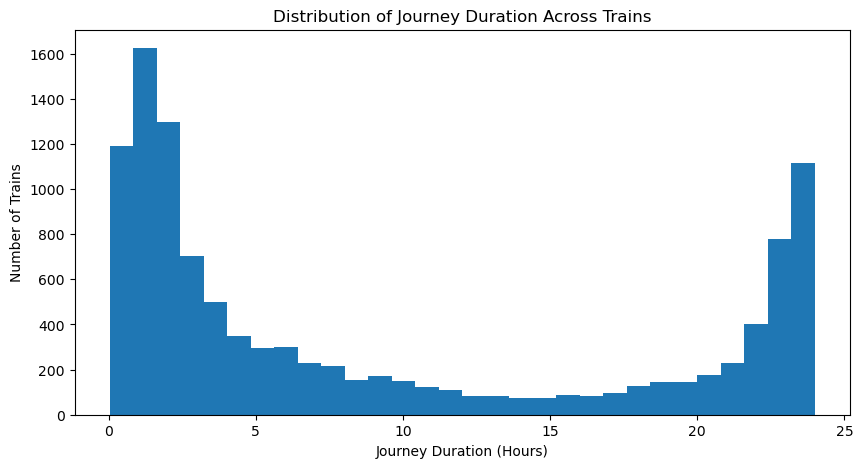

In [3]:
plt.figure(figsize=(10,5))
plt.hist(journey_duration["Journey_Duration_Hours"], bins=30)
plt.xlabel("Journey Duration (Hours)")
plt.ylabel("Number of Trains")
plt.title("Distribution of Journey Duration Across Trains")
plt.show()


In [4]:
station_traffic = df.groupby("Station_Name")["Train_No"].count()


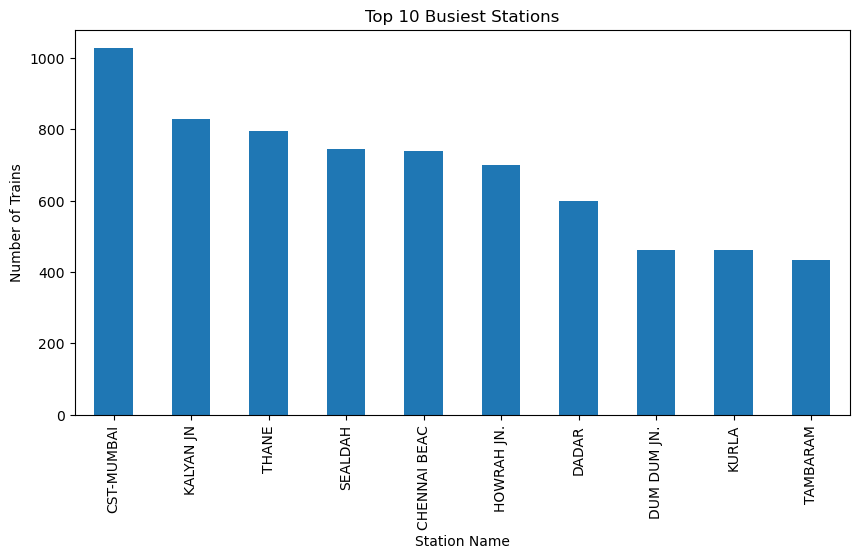

In [5]:
top_stations = station_traffic.sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
top_stations.plot(kind="bar")
plt.xlabel("Station Name")
plt.ylabel("Number of Trains")
plt.title("Top 10 Busiest Stations")
plt.show()


In [6]:
distance_duration = df.groupby("Train_No").agg(
    Total_Distance=("Distance", "max"),
    Start_Time=("Arrival_time", "min"),
    End_Time=("Departure_Time", "max")
)

distance_duration["Journey_Duration_Hours"] = (
    distance_duration["End_Time"] - distance_duration["Start_Time"]
).dt.total_seconds() / 3600


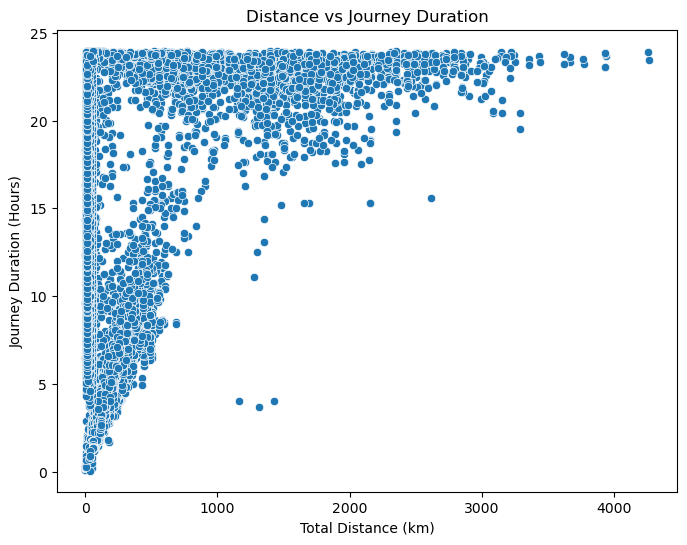

In [7]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="Total_Distance",
    y="Journey_Duration_Hours",
    data=distance_duration
)
plt.xlabel("Total Distance (km)")
plt.ylabel("Journey Duration (Hours)")
plt.title("Distance vs Journey Duration")
plt.show()
